In [2]:
import pandas as pd
import numpy as np

In [3]:
df = pd.read_csv("powerplant_data.csv")

In [4]:
df.head()

,AT,V,AP,RH,PE
0,8.34,40.77,1010.84,90.01,480.48
1,23.64,58.49,1011.40,74.20,445.75
2,29.74,56.90,1007.15,41.91,438.76
3,19.07,49.69,1007.22,76.79,453.09
4,11.80,40.66,1017.13,97.20,464.43


In [5]:
df.isnull().sum()

AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64

In [6]:
X = df.drop(columns = ["PE"])
y = df["PE"]

In [7]:
y.head()

0    480.48
1    445.75
2    438.76
3    453.09
4    464.43
Name: PE, dtype: float64

In [8]:
# size of data
df.shape

(9568, 5)

In [9]:
# split the data

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [10]:
# Scaling the data so no single feature dominate

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [11]:
X_train_scaled

array([[ 0.74805289,  0.72006931, -0.32660017, -0.49711722],
       [ 0.86181948,  1.26515721, -0.98521113,  0.8181501 ],
       [ 0.93409473,  1.52314975,  0.32523844,  0.80167494],
       ...,
       [-0.22097078, -0.834965  ,  0.36756563, -0.83554456],
       [ 0.94747903,  1.14245344, -0.41971997, -0.45455637],
       [-1.77355014, -1.19049131,  1.92520594,  0.91837402]],
      shape=(7654, 4))

In [12]:
import torch
import torch.nn as nn

# data -> tensor 
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32).view(-1,1)

X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.float32).view(-1,1)

In [13]:
type(X_train_scaled)

numpy.ndarray

In [14]:
type(y_train)

pandas.core.series.Series

In [15]:
from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

In [16]:
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32)

## Deep Learning

In [17]:
# Define the architeture of Ann

class ANN(nn.Module):
    def __init__(self):
        super(ANN, self).__init__()

        self.model = nn.Sequential(
            # 1st hidden layer
            nn.Linear(X_train.shape[1], 6),
            nn.ReLU(),

            #2nd hidden layer
            nn.Linear(6,6),
            nn.ReLU(),

            # output layer
            nn.Linear(6, 1)
        )

    def forward(self, x):
        return self.model(x)

In [18]:
import torch.optim as optim

model = ANN()

# Loss, optimizer
crietrion = nn.MSELoss()
optimizer = optim.Adam(model.parameters())

In [19]:
# Train the ANN
epochs = 100
train_losses = []
val_losses = []
best_val_loss = float("inf")

for epoch in range(epochs):
    model.train()
    running_loss = 0.0 # total training loss for 1 epochs

    for xb, yb in  train_loader:
        # xb  features of 1 batch
        # yb  labels of 1 batch
        optimizer.zero_grad()
        
        outputs = model(xb)  # forward prop... predicted output for this batch
        loss = crietrion(outputs, yb) # loss compute
        loss.backward() # backward prop.. compute gradient
        optimizer.step() # update params

        running_loss += loss.item()  # loss is in tensor -> convert py float

    epoch_train_loss = running_loss/len(train_loader)
    train_losses.append(epoch_train_loss)


    # Validation
    model.eval()
    running_val_loss = 0.0

    with torch.no_grad(): # no graidents compute
        for xb, yb in train_loader:
            outputs = model(xb)
            loss = crietrion(outputs, yb)
            running_val_loss += loss.item()

        epoch_val_loss = running_val_loss/len(train_loader)
        val_losses.append(epoch_val_loss)
            
    print(f" epoch {epoch+1}/{epochs} ==> train loss {epoch_train_loss} & val = {epoch_val_loss}")

    if(epoch_val_loss < best_val_loss):
        best_val_loss = epoch_val_loss
        torch.save(model.state_dict(), "best_model.pt") # file pt/pth for saving best params of model

 epoch 1/100 ==> train loss 205564.41145833334 & val = 202855.2080078125
 epoch 2/100 ==> train loss 192599.83821614584 & val = 176851.91126302083
 epoch 3/100 ==> train loss 150648.5775716146 & val = 120372.27685546875
 epoch 4/100 ==> train loss 88830.46510416667 & val = 59767.153987630205
 epoch 5/100 ==> train loss 41169.446317545575 & val = 28089.772005208335
 epoch 6/100 ==> train loss 22832.843033854166 & val = 19506.623311360676
 epoch 7/100 ==> train loss 17667.655847167967 & val = 15987.227598063151
 epoch 8/100 ==> train loss 14498.020768229168 & val = 12934.98051554362
 epoch 9/100 ==> train loss 11482.103676350911 & val = 10016.049291992187
 epoch 10/100 ==> train loss 8635.73607788086 & val = 7306.487643432617
 epoch 11/100 ==> train loss 6101.439942932129 & val = 4959.948984781901
 epoch 12/100 ==> train loss 4012.104185994466 & val = 3131.1761627197266
 epoch 13/100 ==> train loss 2461.7739990234377 & val = 1868.4506673177084
 epoch 14/100 ==> train loss 1452.6634457906

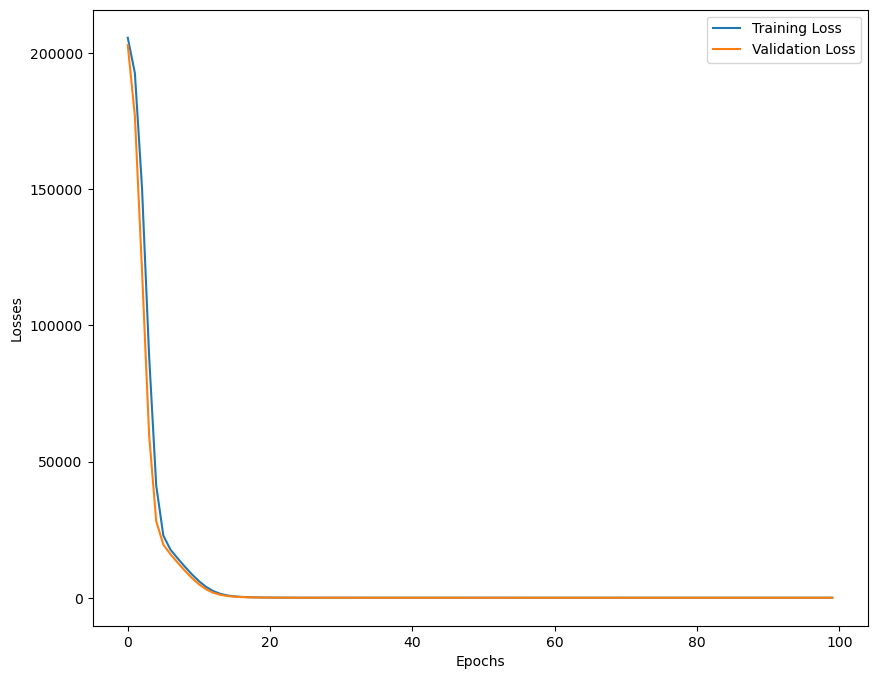

In [20]:
import matplotlib.pyplot as plt

loss_df =  pd.DataFrame({
    "Training Loss": train_losses,
    "Validation Loss": val_losses
})

plt.figure(figsize=(10,8))
plt.plot(loss_df["Training Loss"], label="Training Loss")
plt.plot(loss_df["Validation Loss"], label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Losses")
plt.legend()


In [21]:
# loading the best model
model.load_state_dict(torch.load("best_model.pt")) # loaded best params then given to model

<All keys matched successfully>

In [22]:
# Evaluation

model.eval()

with torch.no_grad():
    train_preds = model(X_train_tensor)
    test_preds = model(X_test_tensor)

    train_mse_loss = crietrion(train_preds, y_train_tensor)
    test_mse_loss = crietrion(test_preds, y_test_tensor)

print(f"Train MSE : {train_mse_loss}")
print(f"Test MSE : {test_mse_loss}")

Train MSE : 20.34817123413086
Test MSE : 18.839073181152344


In [23]:
from sklearn.metrics import r2_score

print(f" r2 score Test : ", r2_score(y_test, test_preds))

 r2 score Test :  0.9341623047158202


In [24]:
predicted_df = pd.DataFrame(test_preds.numpy(), columns=["Predicted Values"])
actual_df = pd.DataFrame(y_test.values, columns=["Actual Values"])

pd.concat([predicted_df, actual_df], axis=1)

,Predicted Values,Actual Values
0,435.293854,433.27
1,436.706573,438.16
2,461.333771,458.42
3,476.518890,480.82
4,434.988342,441.41
...,...,...
1909,451.523926,456.70
1910,431.424316,438.04
1911,468.194550,467.80
1912,430.789764,437.14
